In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

In [2]:
plt.rcParams["font.family"] = "Arial Unicode MS"
df = pd.read_csv("../data/processed/survival_2015.csv")
df.head()

,統一編號,公司名稱,county,capital,setup_date,dissolve_date,end_date,duration_months,event
0,24829970,全創興業有限公司,臺中市,500000,2015-01-01,NaN,2026-09-30,140.932983,0
1,24829985,鳴聲有限公司,臺中市,1000000,2015-01-04,2020-07-20,2020-07-20,66.491459,1
2,24858741,海砡實業有限公司,花蓮縣,100000,2015-01-05,2016-01-21,2016-01-21,12.516426,1
3,54395536,德商柏朗有限公司,臺南市,0,2015-01-05,NaN,2026-09-30,140.801577,0
4,24784397,鋐翰科技股份有限公司,臺北市,500000,2015-01-05,2018-11-19,2018-11-19,46.452037,1


# ==================== A. 依資本額分組 ====================

In [3]:
# 排除資本額為 0 或缺漏的公司（多半是外國公司分公司）
cap = df[df["capital"] > 0].copy()
print("排除資本額為 0 或缺漏：", len(df) - len(cap), "家")

排除資本額為 0 或缺漏： 302 家


In [4]:
# 把資本額切成 4 組
cap["capital_group"] = pd.cut(
    cap["capital"],
    bins=[0, 500_000, 1_000_000, 5_000_000, float("inf")],
    labels=["50萬以下", "50萬～100萬", "100萬～500萬", "500萬以上"],
)
print(cap["capital_group"].value_counts().sort_index())

capital_group
50萬以下        14843
50萬～100萬     11946
100萬～500萬    11741
500萬以上        5102
Name: count, dtype: int64


50萬以下 5 年存活率： 0.739
50萬～100萬 5 年存活率： 0.783
100萬～500萬 5 年存活率： 0.81
500萬以上 5 年存活率： 0.833


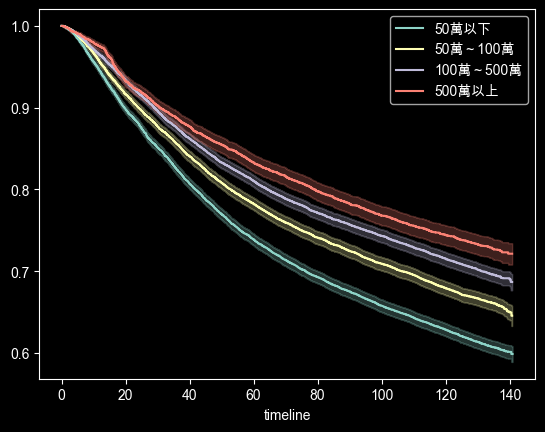

In [5]:
# 每一組各畫一條 KM 曲線
fig, ax = plt.subplots()
for group in cap["capital_group"].cat.categories:
    sub = cap[cap["capital_group"] == group]
    kmf = KaplanMeierFitter()
    kmf.fit(sub["duration_months"], sub["event"], label=group)
    kmf.plot_survival_function(ax=ax)
    print(group, "5 年存活率：", round(kmf.survival_function_at_times(60).iloc[0], 3))

In [6]:
# log-rank test：各組是否有顯著差異
result = multivariate_logrank_test(cap["duration_months"], cap["capital_group"], cap["event"])
print("資本額 log-rank p 值：", result.p_value)

資本額 log-rank p 值： 6.170831074629144e-81


In [7]:
ax.set_xlabel("成立後月數")
ax.set_ylabel("存活率")
ax.set_title("依資本額分組的存活曲線")
ax.set_ylim(0, 1)
plt.savefig("../reports/figures/km_by_capital.png", dpi=150)
plt.show()


<Figure size 640x480 with 0 Axes>

# ==================== B. 依縣市分組 ====================

臺北市 5 年存活率： 0.755
新北市 5 年存活率： 0.78
臺中市 5 年存活率： 0.788
高雄市 5 年存活率： 0.803
桃園市 5 年存活率： 0.782
臺南市 5 年存活率： 0.808
縣市 log-rank p 值： 1.8739801155548116e-13


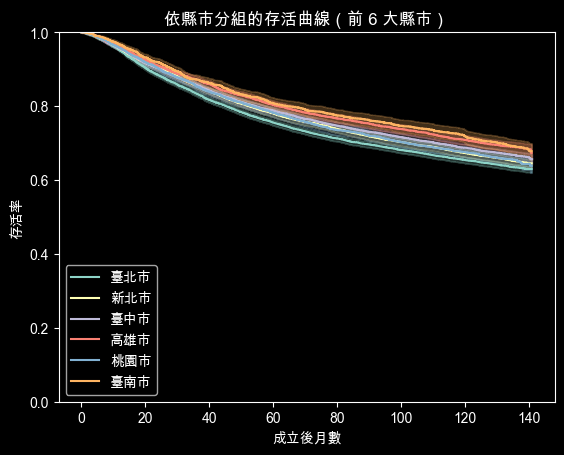

In [8]:
# 只取公司數最多的 6 個縣市，不然線太多看不清楚
top_counties = df["county"].value_counts().index[:6]
cty = df[df["county"].isin(top_counties)]

fig, ax = plt.subplots()
for county in top_counties:
    sub = cty[cty["county"] == county]
    kmf = KaplanMeierFitter()
    kmf.fit(sub["duration_months"], sub["event"], label=county)
    kmf.plot_survival_function(ax=ax)
    print(county, "5 年存活率：", round(kmf.survival_function_at_times(60).iloc[0], 3))

result = multivariate_logrank_test(cty["duration_months"], cty["county"], cty["event"])
print("縣市 log-rank p 值：", result.p_value)

ax.set_xlabel("成立後月數")
ax.set_ylabel("存活率")
ax.set_title("依縣市分組的存活曲線（前 6 大縣市）")
ax.set_ylim(0, 1)
plt.savefig("../reports/figures/km_by_county.png", dpi=150)
plt.show()